In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
jam = rng.uniform(1, 9, size=60)
nilai = 35 + 5 * jam + rng.normal(
    loc=0, scale=6, size=60
)
df = pd.DataFrame({"jam_belajar" : jam,
                   "nilai_ujian" : nilai})

In [9]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [10]:
df.shape

(60, 2)

In [11]:
df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [12]:
df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


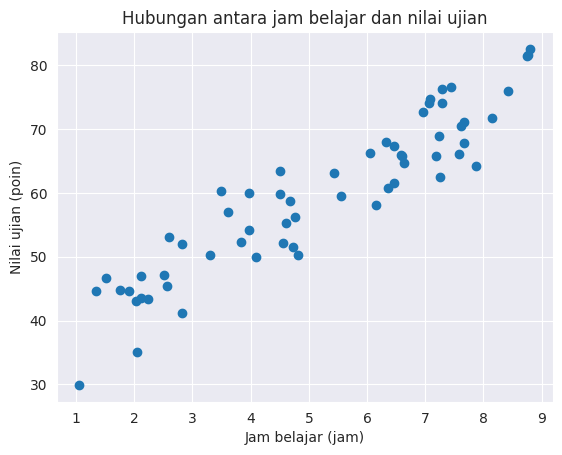

In [18]:
import matplotlib.pyplot as plt

plt.scatter(df['jam_belajar'],
            df['nilai_ujian'])
plt.xlabel('Jam belajar (jam)')
plt.ylabel('Nilai ujian (poin)')
plt.title('Hubungan antara jam belajar dan nilai ujian')
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

x = df['jam_belajar']
y = df['nilai_ujian']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
  )

In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train.values.reshape(-1, 1), y_train)

LinearRegression()

In [35]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"Model Colab: nilai_prediksi = "
      f"{b0:.3f} + ({b1:.3f}) x jam_belajar")

Model Colab: nilai_prediksi = 34.524 + (4.933) x jam_belajar


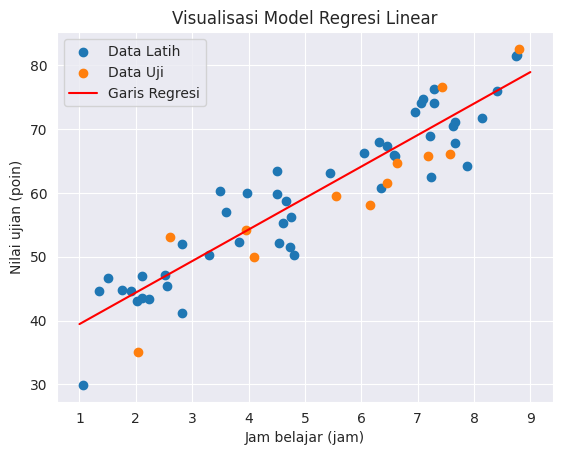

In [32]:
x_grid = pd.DataFrame(
    {"jam_belajar": np.linspace(1, 9, 100)})
y_grid = model.predict(x_grid.values)
plt.scatter(x_train, y_train, label='Data Latih')
plt.scatter(x_test, y_test, label='Data Uji')
plt.plot(x_grid["jam_belajar"], y_grid, color='red', label='Garis Regresi')
plt.xlabel('Jam belajar (jam)')
plt.ylabel('Nilai ujian (poin)')
plt.title('Visualisasi Model Regresi Linear')
plt.legend()
plt.show()

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_test = model.predict(x_test.values.reshape(-1, 1))
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2: {r2:.3f}")

MAE: 4.730
RMSE: 5.239
R2: 0.804
